# 02 - Tier 1: VADER (rule-based)

Every model is scored with the shared code in `src/eval_utils.py`, on the same frozen `test300` subset and the 30 hard cases.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt

from src.data_utils import load_split, LABELS
from src.eval_utils import evaluate_model, hard_case_breakdown, score

## 0. Reference: majority-class baseline
Always predicts the most common **training** label. This is the floor every real model must beat, and an end-to-end test of the evaluation code.

Majority training label: positive


model                                       Majority baseline
accuracy                                               0.5033
macro_f1                                               0.3348
hard_cases_acc                                            0.5
sec_per_1k                                           0.000005
cost_per_1k                                               0.0
n_test                                                    300
n_hard                                                     30
evaluated_at                        2026-11-19T10:14:54+00:00
notes             Always predicts the majority training label
dtype: object

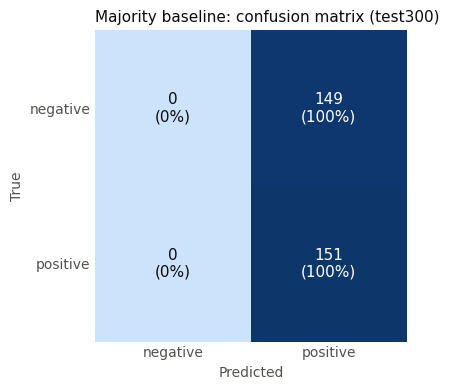

In [2]:
train = load_split('train')
majority = train['label'].value_counts().idxmax()
print('Majority training label:', majority)

def predict_majority(texts):
    return [majority] * len(texts)

baseline = evaluate_model('Majority baseline', predict_majority,
                          notes='Always predicts the majority training label')
pd.Series({k: v for k, v in baseline.items() if k != 'confusion_matrix'})

In [3]:
# Check the harness against hand-computed values:
# test300 has 151 positive / 149 negative. Always predicting 'positive' gives
# accuracy 151/300, positive F1 = 2*(151/300)/(151/300 + 1), negative F1 = 0.
expected_acc = 151 / 300
expected_f1 = (2 * expected_acc / (expected_acc + 1) + 0) / 2
assert majority == 'positive'
assert abs(baseline['accuracy'] - round(expected_acc, 4)) < 1e-9
assert abs(baseline['macro_f1'] - round(expected_f1, 4)) < 1e-9
assert baseline['hard_cases_acc'] == 0.5  # 15 of 30 hard cases are positive
print(f'Harness verified: acc={expected_acc:.4f}, macro-F1={expected_f1:.4f}')

Harness verified: acc=0.5033, macro-F1=0.3348


In [4]:
hard_case_breakdown('Majority baseline')

,accuracy,correct,n
category,,,
faint_praise,0.000000,0,3
sarcasm,0.000000,0,3
negation,0.333333,1,3
comparison,0.500000,1,2
rating,0.500000,1,2
rhetorical_question,0.500000,1,2
idiom,0.500000,1,2
contrast,0.666667,2,3
domain_polarity,0.666667,2,3


## 1. VADER
VADER scores each word against a hand-built lexicon and adjusts for negation, intensifiers ("very"), capitals, "!" and "but". It returns a `compound` score from -1 to +1. Nothing is trained.

**Label mapping.** VADER's usual cut-offs (>= 0.05 positive, <= -0.05 negative, neutral between) give three classes, but this dataset has only two. The default rule is **compound >= 0 -> positive**, otherwise negative.

In [5]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()
VADER_THRESHOLD = 0.0

def vader_compound(texts):
    return [analyzer.polarity_scores(t)['compound'] for t in texts]

def make_vader_predictor(threshold):
    def predict(texts):
        return ['positive' if c >= threshold else 'negative' for c in vader_compound(texts)]
    return predict

for s in ['great movie', 'not great', 'NOT GREAT!!!', 'good acting, but a terrible plot']:
    print(f"{s!r:40} compound={analyzer.polarity_scores(s)['compound']:+.3f}")

'great movie'                            compound=+0.625
'not great'                              compound=-0.510
'NOT GREAT!!!'                           compound=-0.633
'good acting, but a terrible plot'       compound=-0.494


### 1.1 Is 0 a good threshold? Check on a train sample only
A sweep on 2,000 **training** reviews (the test set is never used for tuning). It shows whether a different threshold would help and how VADER's scores are distributed on long reviews.

In [6]:
tune = train.sample(2000, random_state=42)
tune_compound = pd.Series(vader_compound(tune['text'].tolist()), index=tune.index)

sweep = pd.DataFrame([
    {'threshold': th, **score(tune['label'],
        ['positive' if c >= th else 'negative' for c in tune_compound])}
    for th in [-0.5, -0.25, 0.0, 0.25, 0.5, 0.75, 0.9, 0.95]
]).round(4)
best = sweep.loc[sweep['macro_f1'].idxmax()]
print(f"Best train-sample threshold: {best['threshold']} (macro-F1 {best['macro_f1']})")
sweep

Best train-sample threshold: 0.75 (macro-F1 0.717)


,threshold,accuracy,macro_f1
0,-0.50,0.6665,0.6555
1,-0.25,0.6870,0.6800
2,0.00,0.6915,0.6862
3,0.25,0.7065,0.7038
4,0.50,0.7140,0.7129
5,0.75,0.7170,0.7170
6,0.90,0.7190,0.7162
7,0.95,0.6955,0.6833


In [7]:
# Where do compound scores fall for each true class? (train sample)
bands = pd.cut(tune_compound, [-1.001, -0.5, -0.05, 0.05, 0.5, 1.0],
               labels=['<= -0.5', '-0.5 to -0.05', 'neutral (+/-0.05)', '0.05 to 0.5', '>= 0.5'])
pd.crosstab(bands, tune['label'], normalize='columns').round(3)

label,negative,positive
row_0,,
<= -0.5,0.465,0.111
-0.5 to -0.05,0.064,0.023
neutral (+/-0.05),0.017,0.003
0.05 to 0.5,0.076,0.047
>= 0.5,0.378,0.816


### 1.2 Score VADER on test300 and the hard cases

model                                                VADER
accuracy                                            0.7267
macro_f1                                            0.7153
hard_cases_acc                                      0.3333
sec_per_1k                                        4.675349
cost_per_1k                                            0.0
n_test                                                 300
n_hard                                                  30
evaluated_at                     2026-11-19T10:15:09+00:00
notes             compound >= 0.0 -> positive; no training
dtype: object

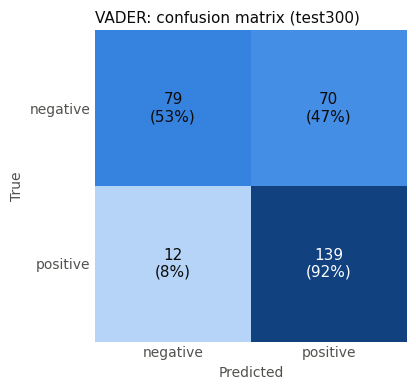

In [8]:
vader = evaluate_model(
    'VADER', make_vader_predictor(VADER_THRESHOLD),
    notes=f'compound >= {VADER_THRESHOLD} -> positive; no training',
)
pd.Series({k: v for k, v in vader.items() if k != 'confusion_matrix'})

In [9]:
hard_case_breakdown('VADER')

,accuracy,correct,n
category,,,
dark_plot_summary,0.000000,0,2
double_negative,0.000000,0,2
idiom,0.000000,0,2
slang_emoji,0.000000,0,3
sarcasm,0.000000,0,3
domain_polarity,0.333333,1,3
faint_praise,0.333333,1,3
comparison,0.500000,1,2
rhetorical_question,0.500000,1,2


In [10]:
# Hard cases VADER got wrong (the hand-written set, not test data)
from src.data_utils import load_hard_cases
hard = load_hard_cases()
hard['compound'] = vader_compound(hard['text'].tolist())
hard['pred'] = ['positive' if c >= VADER_THRESHOLD else 'negative' for c in hard['compound']]
with pd.option_context('display.max_colwidth', 90):
    display(hard.loc[hard['pred'] != hard['label'],
                     ['id', 'category', 'label', 'compound', 'text']].round(3))

,id,category,label,compound,text
3,4,double_negative,positive,-0.522,There wasn't a single scene I didn't love.
4,5,double_negative,positive,-0.276,It's impossible not to smile during this film.
5,6,sarcasm,negative,0.401,"Oh great, another two hours of my life I'll never get back. Thanks, Hollywood."
6,7,sarcasm,negative,0.836,"Wow, what a masterpiece. I only checked my phone forty times."
7,8,sarcasm,negative,0.827,"If you enjoy watching paint dry, you'll absolutely love this one."
10,11,contrast,positive,-0.090,"It starts slow and the first half drags, but the ending more than makes up for it."
11,12,dark_plot_summary,positive,-0.951,"A brutal, harrowing story of war, murder and grief, and the most moving film I've seen..."
12,13,dark_plot_summary,positive,-0.542,"It follows a lonely, depressed man whose family dies in a fire; it is beautifully acte..."
14,15,domain_polarity,positive,-0.813,"Terrifying from start to finish, exactly what a horror film should be."
15,16,domain_polarity,negative,0.250,"The twist was predictable from the first ten minutes, and the jokes were even more pre..."


## 2. TextBlob (secondary rule-based comparison)
TextBlob uses the Pattern lexicon of adjective polarities and returns `polarity` from -1 to +1. The same binary rule is used: polarity >= 0 -> positive.

model                                           TextBlob
accuracy                                            0.71
macro_f1                                          0.6872
hard_cases_acc                                       0.4
sec_per_1k                                       2.10408
cost_per_1k                                          0.0
n_test                                               300
n_hard                                                30
evaluated_at                   2026-11-19T10:15:13+00:00
notes             polarity >= 0 -> positive; no training
dtype: object

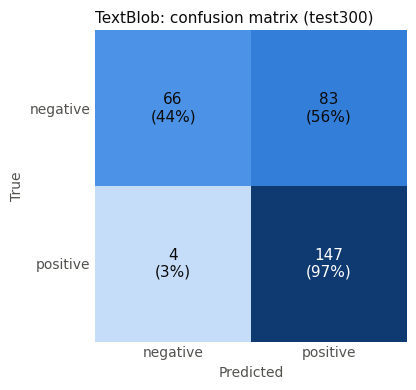

In [11]:
from textblob import TextBlob

def predict_textblob(texts):
    return ['positive' if TextBlob(t).sentiment.polarity >= 0 else 'negative' for t in texts]

textblob = evaluate_model('TextBlob', predict_textblob,
                          notes='polarity >= 0 -> positive; no training')
pd.Series({k: v for k, v in textblob.items() if k != 'confusion_matrix'})

## 3. Tier 1 summary

In [12]:
from src.eval_utils import METRICS_PATH
pd.read_csv(METRICS_PATH).set_index('model')[
    ['accuracy', 'macro_f1', 'hard_cases_acc', 'sec_per_1k', 'cost_per_1k']]

,accuracy,macro_f1,hard_cases_acc,sec_per_1k,cost_per_1k
model,,,,,
NLTK + Naive Bayes,0.8867,0.8867,0.7000,3.609593,0.000
LLM zero-shot (Haiku 5.5),0.9567,0.9567,1.0000,1560.301000,0.075
Majority baseline,0.5033,0.3348,0.5000,0.000005,0.000
VADER,0.7267,0.7153,0.3333,4.675349,0.000
TextBlob,0.7100,0.6872,0.4000,2.104080,0.000


### Notes

**Results on test300**

| Model | Accuracy | Macro-F1 | Hard-cases acc. | Sec / 1k | Cost / 1k |
|---|---|---|---|---|---|
| Majority baseline | 0.503 | 0.335 | 0.50 | ~0 | $0 |
| VADER | 0.727 | 0.715 | 0.33 | 4.7 | $0 |
| TextBlob | 0.710 | 0.687 | 0.40 | 2.1 | $0 |

**Both lexicons lean strongly positive.**
- VADER labels 47% of negative reviews (70 of 149) as positive, but only 8% of positive reviews as negative. TextBlob is worse: 56% (83 of 149) of negative reviews become positive.
- The cause is that negative IMDB reviews still contain plenty of positive words: praise for one actor, ironic "great", or "good" in comparisons with other films. Summed over roughly 230 words, those words win. In the train sample, 38% of negative reviews score compound >= 0.5.
- The train-sample sweep confirms the bias is systematic. A threshold of 0.75 lifts macro-F1 from 0.686 to 0.717, about 3 points.
- The main VADER row keeps the threshold at 0 so Tier 1 stays truly training-free. A tuned threshold would be a light calibration step learned from training data.

**Hard cases: VADER scores 10 of 30 (0.33), below the 0.50 coin flip.**
- Its negation rule works: it got all 3 negation cases right ("not bad", "can't say I enjoyed").
- It failed every case in double negatives, sarcasm, dark plot summary, idioms and slang/emoji. Examples:
  - "absolutely killed it": compound -0.70 (should be positive)
  - "this movie is sick 🔥🔥 no cap": -0.85 (should be positive)
  - "Wow, what a masterpiece. I only checked my phone forty times.": +0.84 (should be negative)
  - "A brutal, harrowing story of war, murder and grief, and the most moving film…": -0.95 (should be positive)
- Sentences with no lexicon words score exactly 0.00 ("fell flat and never got off the ground", "zero stars"). They default to positive under the >= 0 rule.

**Speed and cost.** Everything runs locally for free: about 4.7 ms per review for VADER and 2.1 ms for TextBlob (final run; local timings vary by about ±30% between runs), on reviews averaging 230 words.

**Takeaway.** Tier 1 gets about 72% accuracy for free, but it is biased toward positive and fails on exactly the language that needs context. That sets the bar Tiers 2 and 3 have to beat.